## 1. Introduction
### Pima Indians Diabetes Project🍫


- This project explores how machine learning can be used to predict diabetes using basic clinical measurements.
-Using the Pima Indians Diabetes dataset, several classification models were trained to identify whether a patient is likely to have diabetes.

- The goal of this project is to build a simple and reproducible machine learning pipeline that includes data cleaning, preprocessing, model training, and model evaluation on real medical data.

**Dataset**
Pima Indians Diabetes Dataset (UCI Machine Learning Repository)

768 patient records
8 clinical features: Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age
Target variable:
0 = No diabetes
1 = Diabetes

**Methods**
The following steps were implemented in the project:
- Data cleaning and handling of medically invalid values
- Exploratory Data Analysis (EDA)
- Preprocessing pipeline (imputation and feature scaling)
- Training multiple classification models
- Model evaluation using accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices
- Identifying the most important predictors of diabetes
- 
**Note**
All analysis, visualizations, and code implementations in this project were developed independently as part of a self‑directed learning project in computational biology.

### Research Questions
This project aims to answer the following questions:

- Can machine learning models predict diabetes using basic clinical measurements?
- Which physiological features are the most important predictors of diabetes?
- Which model performs better for this dataset: Logistic Regression or Random Forest?
- How well can the models identify true diabetes cases?

## 2. Importing Required Libraries
Import libraries for data handling, visualization, modeling, and evaluation


In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Basic plot settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)

# Model selection and evaluation
from sklearn.model_selection import train_test_split, cross_validate, cross_val_predict, cross_val_score, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
# Preprocessing and Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier


## 3. Load the dataset & define columns

In [7]:
# Load the dataset 

columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

df = pd.read_csv("../data/diabetes.csv")

# .. means go up one directory, from notebooks to the project root.
# data/ means enter the data folder.
# diabetes.csv is the file to load.


--------------------------------


## 4. Exploratory Data Analysis (EDA)
###  Data Inspection & Descriptive Statistics

4.1 Check number of rows and columns using df.shape :

In [8]:
print("Dataset shape:", df.shape)

Dataset shape: (768, 9)


- This dataset has 768 samples and 9 columns (8 features + target).


---






4.2 The first 5 rows to understand the dataset structure using df.head() :

In [9]:
print("\nFirst 5 rows:\n", df.head())  # Preview the data


First 5 rows:
    Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


---

4.3 Check Data Types & Missing Values  Using info():


In [10]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


- The dataset contains 768 observations, eight predictor features, and one binary target variable (`Outcome`).
-  Although no explicit missing values are reported at this stage, some measurements are represented by zero values that require domain-specific investigation.

---

4.4 Class distribution

In [11]:
# Map numeric labels to meaningful class names
class_mapping = {
    0: "Non-Diabetic",
    1: "Diabetic"
}

# Calculate normalized class distribution
class_dist = df['Outcome'].value_counts(normalize=True).round(3)

# Apply mapping for readability
class_dist.index = class_dist.index.map(class_mapping)

print("\nClass distribution:")
print(class_dist)



Class distribution:
Outcome
Non-Diabetic    0.651
Diabetic        0.349
Name: proportion, dtype: float64


- The target distribution is `moderately imbalanced`: approximately 65.1% of observations belong to the non-diabetic class and 34.9% to the diabetic class.
- This difference should be considered when evaluating model performance.
- Accuracy alone may not adequately reflect the model's ability to identify diabetic cases, so recall, precision, F1-score, and ROC-AUC should also be examined.

---



4.5 Summary Statistics of Dataset Using df.describe()

In [12]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


- Zero values appear in `Glucose, BloodPressure, SkinThickness, Insulin, and BMI`.
- Zero values in Glucose, BloodPressure, and BMI are physiologically implausible.
- Zero values in SkinThickness and Insulin are treated as potentially missing or unrecorded measurements.
- Zero values in Pregnancies are valid and should be preserved.


These findings indicate that some values require further handling before model training.

---

## 5. Data Cleaning: Handling Invalid Zero Values

- Based on the findings from the exploratory analysis, zero values in the five selected measurement columns were converted to `NaN`.
- This allows missing measurements to be handled explicitly during preprocessing.
- Zero values in `Pregnancies` were preserved because they are valid observations.
- Imputation parameters will be learned within the training pipeline to prevent data leakage.

In [13]:
# Identify columns where zero values are invalid (medically impossible)
cols_with_invalid_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']


# Replace 0 with NaN (Not a Number) in these specific columns
# This prevents the model from treating missing data as actual physiological values
df[cols_with_invalid_zeros] = df[cols_with_invalid_zeros].replace(0, np.nan)


# Count and display the number of missing values (NaN) in each column
print("Number of missing values (NaN) per column:")
print(df.isnull().sum())


Number of missing values (NaN) per column:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


Statistical operations after data cleaning :

In [14]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,763.000000,733.000000,541.000000,394.000000,757.000000,768.000000,768.000000,768.000000
mean,3.845052,121.686763,72.405184,29.153420,155.548223,32.457464,0.471876,33.240885,0.348958
std,3.369578,30.535641,12.382158,10.476982,118.775855,6.924988,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,64.000000,22.000000,76.250000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,141.000000,80.000000,36.000000,190.000000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


#### Summary Statistics After Cleaning

- After converting selected zero values to missing values, the observed counts differ across features.
- Insulin and SkinThickness have the highest levels of missingness, which may affect the reliability of subsequent analysis.
- The descriptive statistics now summarize the available non-missing observations.
- Missing values will be handled during model preprocessing rather than by deleting large numbers of rows.

#### missingness percentage


In [15]:

# Quantify missing values by feature.
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing_Percent",
    ascending=False
)

display(missing_summary)


,Missing_Count,Missing_Percent
Insulin,374,48.70
SkinThickness,227,29.56
BloodPressure,35,4.56
BMI,11,1.43
Glucose,5,0.65
Pregnancies,0,0.00
DiabetesPedigreeFunction,0,0.00
Age,0,0.00
Outcome,0,0.00


- For this dataset, Insulin should show approximately 48.7% missingness, while SkinThickness should show approximately 29.6%.

-----------------------

## 6. Data Visualization

This section provides a visual and statistical overview of the dataset.

### 6.1 KDE (Kernel Density Estimate) Plot for Comparing 8 features in Diabetic vs. Healthy individuals

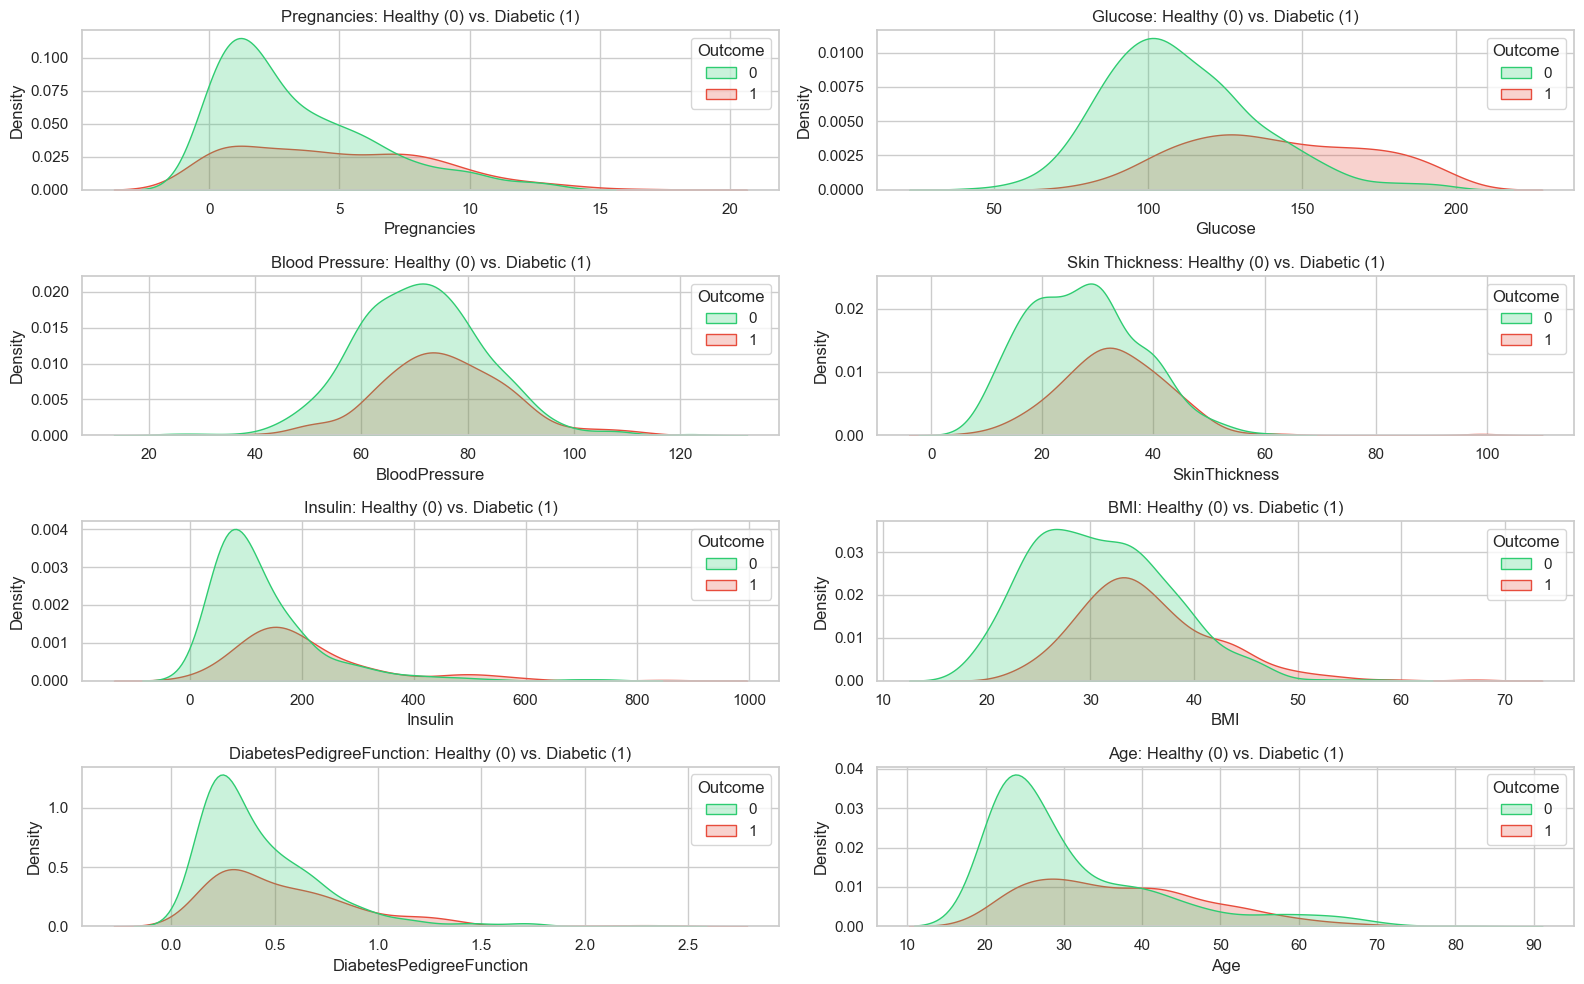

In [16]:
fig, axes = plt.subplots(4, 2, figsize=(16, 10))

# Green for healthy & red for diabetic individuals
my_palette = ['#2ecc71', '#e74c3c']

# KDE Plot for Pregnancies
sns.kdeplot(data=df, x='Pregnancies', hue='Outcome', fill=True, ax=axes[0, 0], palette=my_palette)
axes[0, 0].set_title('Pregnancies: Healthy (0) vs. Diabetic (1)')

# KDE Plot for Glucose
sns.kdeplot(data=df, x='Glucose', hue='Outcome', fill=True, ax=axes[0, 1], palette=my_palette)
axes[0, 1].set_title('Glucose: Healthy (0) vs. Diabetic (1)')

# KDE Plot for BloodPressure 
sns.kdeplot(data=df, x='BloodPressure', hue='Outcome', fill=True, ax=axes[1, 0], palette=my_palette)
axes[1, 0].set_title('Blood Pressure: Healthy (0) vs. Diabetic (1)')

# KDE Plot for SkinThickness
sns.kdeplot(data=df, x='SkinThickness', hue='Outcome', fill=True, ax=axes[1, 1], palette=my_palette)
axes[1, 1].set_title('Skin Thickness: Healthy (0) vs. Diabetic (1)')

# KDE Plot for Insulin
sns.kdeplot(data=df, x='Insulin', hue='Outcome', fill=True, ax=axes[2, 0], palette=my_palette)
axes[2, 0].set_title('Insulin: Healthy (0) vs. Diabetic (1)')

# KDE Plot for BMI
sns.kdeplot(data=df, x='BMI', hue='Outcome', fill=True, ax=axes[2, 1], palette=my_palette)
axes[2, 1].set_title('BMI: Healthy (0) vs. Diabetic (1)')

# KDE Plot for DiabetesPedigreeFunction
sns.kdeplot(data=df, x='DiabetesPedigreeFunction', hue='Outcome', fill=True, ax=axes[3, 0], palette=my_palette)
axes[3, 0].set_title('DiabetesPedigreeFunction: Healthy (0) vs. Diabetic (1)')

# KDE Plot for Age
sns.kdeplot(data=df, x='Age', hue='Outcome', fill=True, ax=axes[3, 1], palette=my_palette)
axes[3, 1].set_title('Age: Healthy (0) vs. Diabetic (1)')



plt.tight_layout()
plt.show()



### Interpretation of KDE Plots

KDE plots compare the estimated distributions of each feature across the two outcome groups. Differences in curve locations, shapes, and overlap suggest potential associations with diabetes status, but they do not establish statistical significance or causation.

- **Pregnancies:** The distribution for Outcome = 1 is shifted toward higher values, suggesting an association between pregnancy count and diabetes status in this dataset.
- **Glucose:** The Outcome = 1 distribution is shifted toward higher glucose levels, making glucose a promising candidate predictor.
- **BloodPressure:** The distributions overlap considerably, suggesting limited separation between the outcome groups based on this feature alone.
- **SkinThickness:** The distributions overlap substantially, so the plot provides limited evidence of clear separation between the groups.
- **Insulin:** Both distributions are right-skewed, with considerable overlap and long upper tails. Differences should be interpreted cautiously because this feature has substantial missingness.
- **BMI:** The Outcome = 1 distribution is shifted toward higher BMI values, suggesting a potential association with diabetes status.
- **DiabetesPedigreeFunction:** The Outcome = 1 distribution appears somewhat shifted toward higher values, although the distributions overlap.
- **Age:** The Outcome = 1 distribution extends toward older ages, suggesting an association between age and diabetes status.

**Overall finding:** Glucose shows one of the clearest distributional differences between the two groups. Several other features also show potential associations, but their independent predictive value must be assessed through model evaluation. These plots are exploratory and do not establish causation or statistical significance.

---

### 6.2 Correlation Heatmap plot for Biological features

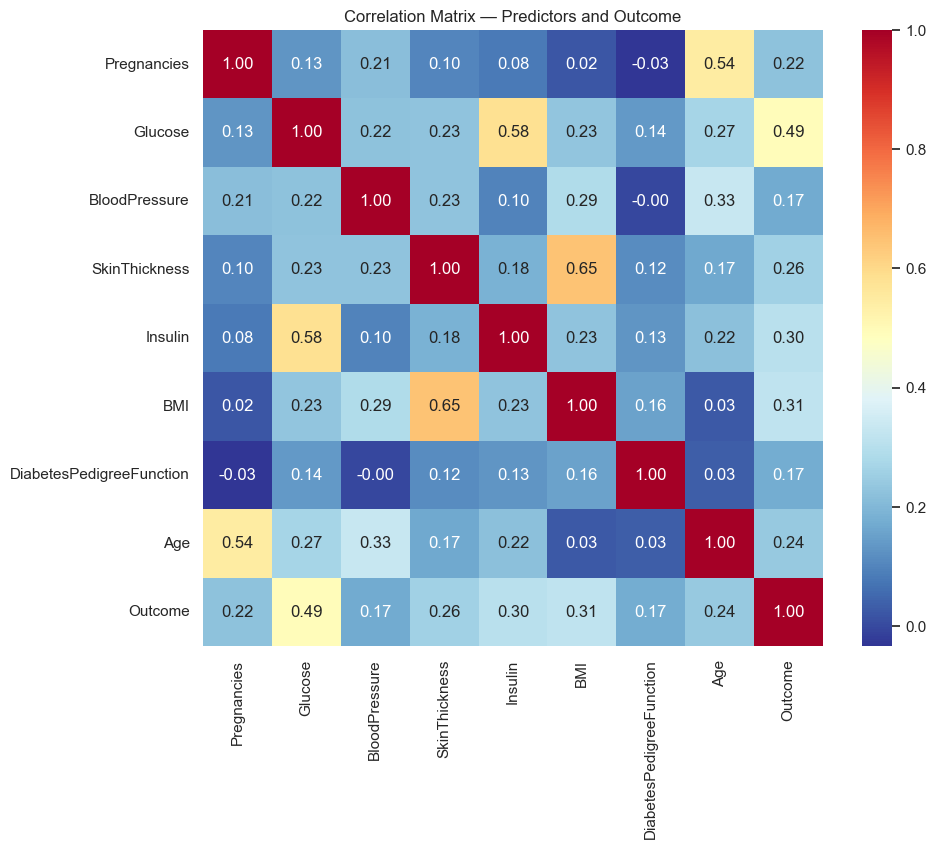

In [17]:
# Create correlation matrix for all features including Outcome
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r"
)

plt.title("Correlation Matrix — Predictors and Outcome")
plt.show()

### Interpretation of the Correlation Heatmap

The heatmap displays Pearson correlation coefficients, which measure the strength and direction of linear relationships between pairs of variables.

- **Glucose and Outcome (0.49):** Glucose has the strongest positive linear correlation with the target among the features shown. Higher glucose values tend to be associated with Outcome = 1.
- **BMI and Outcome (0.31):** BMI has a weaker positive correlation with the target.
- **Insulin and Outcome (0.30):** Insulin shows a positive correlation with the target, although missingness should be considered when interpreting this relationship.
- **SkinThickness and BMI (0.65):** These features have a moderately strong positive correlation, indicating that higher values tend to occur together.
- **Age and Pregnancies (0.54):** Older individuals tend to have higher pregnancy counts in this dataset.
- **BloodPressure and Outcome (0.17):** The linear correlation with the target is relatively weak.

- Glucose has the strongest observed linear association with the target in this heatmap. However, correlation alone does not establish causation or determine a feature's predictive importance. Model evaluation will help establish whether these variables contribute useful predictive information.


---


### 6.3 Histogram Plot of Glucose levels by diabetes status

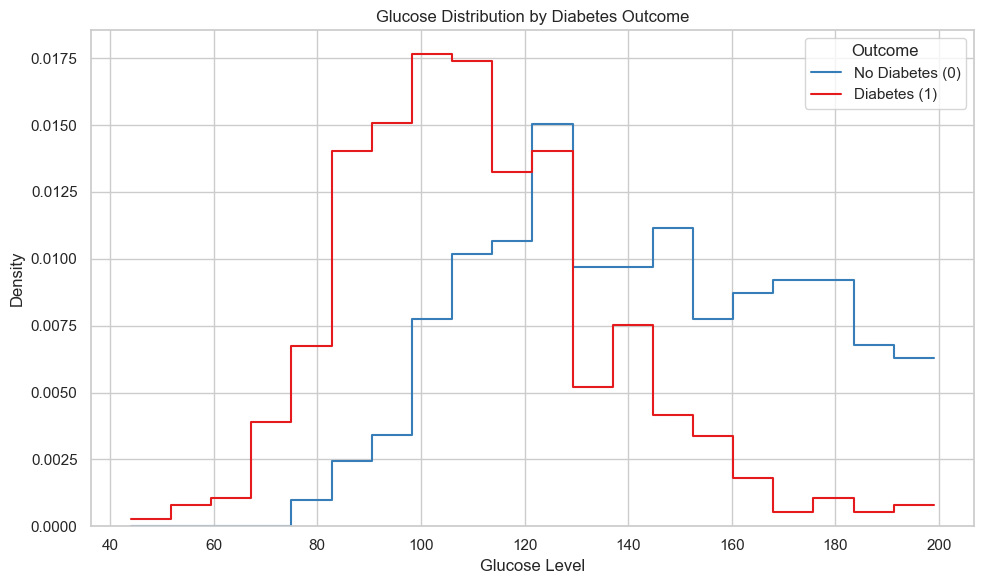

In [18]:
# Compare glucose distributions using normalized histograms
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Glucose",
    hue="Outcome",
    hue_order=[0, 1],
    bins=20,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    palette="Set1"
)

plt.title("Glucose Distribution by Diabetes Outcome")
plt.xlabel("Glucose Level")
plt.ylabel("Density")
plt.legend(
    title="Outcome",
    labels=["No Diabetes (0)", "Diabetes (1)"]
)
plt.tight_layout()
plt.show()


### Interpretation of Glucose Distribution

- The glucose distributions differ between the two outcome groups.
- Observations with Outcome = 1 tend to have higher glucose levels, although the distributions overlap.
- This pattern suggests that glucose may be a useful predictor of diabetes status.
- However, the histogram alone does not establish statistical significance, causation, or the feature's independent predictive contribution.

-------------------------------

### 6.4 Scatter Plot for seeing how Age and Glucose are related to Diabetes


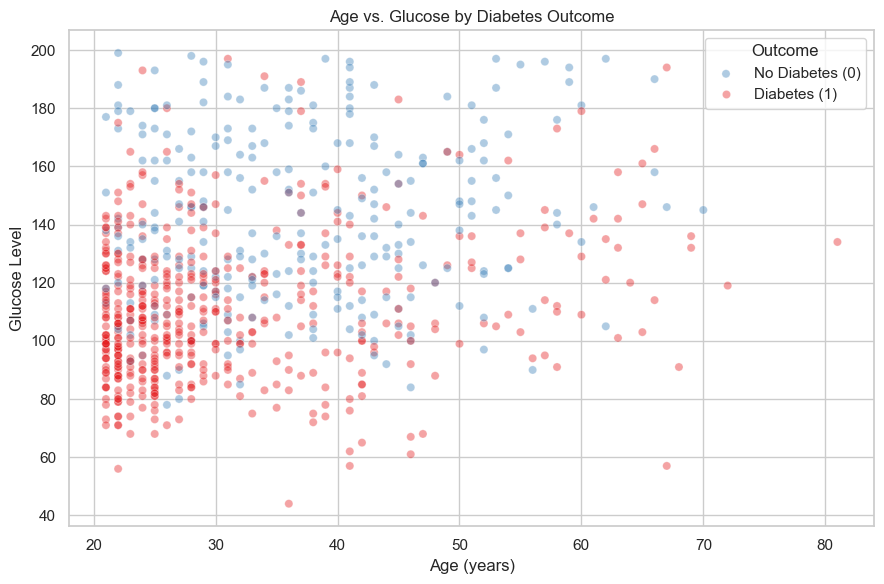

In [19]:
# Explore the relationship between age and glucose
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Glucose",
    hue="Outcome",
    hue_order=[0, 1],
    alpha=0.4,      # Slight transparency to reduce overlap
    s=35,
    palette="Set1"
)

plt.title("Age vs. Glucose by Diabetes Outcome")
plt.xlabel("Age (years)")
plt.ylabel("Glucose Level")
plt.legend(title="Outcome", labels=["No Diabetes (0)", "Diabetes (1)"])
plt.tight_layout()
plt.show()


### Interpretation of Scatter Plot

- Individuals with diabetes (Outcome = 1) tend to show higher glucose levels overall, although the two groups overlap considerably.
- Age alone does not clearly separate individuals with and without diabetes in this dataset.
- Glucose appears to show a clearer association with diabetes status than age in this visualization. However, its relative predictive importance should be evaluated using model performance and feature analysis.

---

### 6.5 Box plot of BMI

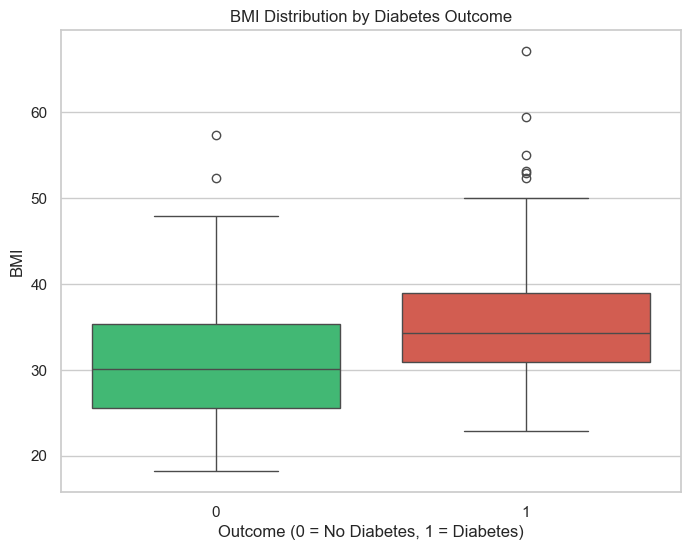

In [20]:
# Boxplot of BMI by diabetes status
plt.figure(figsize=(8, 6))
sns.boxplot(
    x='Outcome',
    y='BMI',
    data=df,
    hue='Outcome',
    palette=['#2ecc71', '#e74c3c'],
    legend=False)
plt.title('BMI Distribution by Diabetes Outcome')
plt.xlabel('Outcome (0 = No Diabetes, 1 = Diabetes)')
plt.ylabel('BMI')
plt.show()

### Interpretation of BMI Distribution

- The median BMI is higher in the Outcome = 1 group than in the Outcome = 0 group.
-  The distributions overlap, and both groups contain observations with relatively high BMI values.
- This suggests an association between BMI and diabetes status in this dataset.
-  The boxplot alone cannot establish causation or determine BMI's independent predictive value.
  
---

### 6.6 Probability of Diabetes by Number of Pregnancies - Bar Plot

,Pregnancies,Observed_Rate,Sample_Size
0,0,0.342342,111
1,1,0.214815,135
2,2,0.184466,103
3,3,0.360000,75
4,4,0.338235,68
5,5,0.368421,57
6,6,0.320000,50
7,7,0.555556,45
8,8,0.578947,38
9,9,0.642857,28


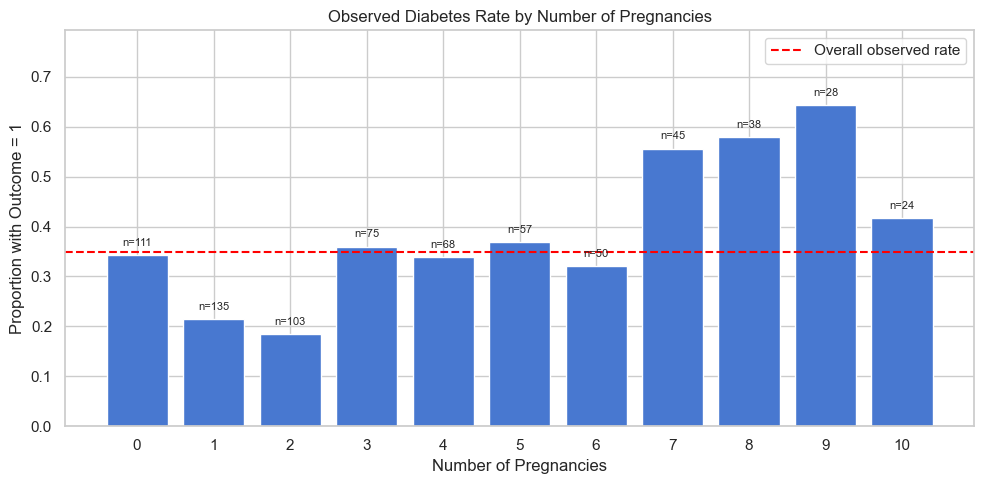

In [21]:
# Estimate the observed positive-outcome rate by pregnancy count
pregnancy_summary = (
    df.groupby("Pregnancies")["Outcome"]
    .agg(["mean", "count"])
    .reset_index()
    .rename(columns={
        "mean": "Observed_Rate",
        "count": "Sample_Size"
    })
)

# Exclude groups with fewer than 15 observations from the plot
reliable_groups = pregnancy_summary[
    pregnancy_summary["Sample_Size"] >= 15
].copy()

display(pregnancy_summary)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    reliable_groups["Pregnancies"].astype(str),
    reliable_groups["Observed_Rate"]
)

# Display the sample size above each bar
for bar, n in zip(bars, reliable_groups["Sample_Size"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"n={n}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.axhline(               
    df["Outcome"].mean(),
    color="red",
    linestyle="--",
    label="Overall observed rate"
)

plt.title("Observed Diabetes Rate by Number of Pregnancies")
plt.xlabel("Number of Pregnancies")
plt.ylabel("Proportion with Outcome = 1")
plt.ylim(0, min(1.15, reliable_groups["Observed_Rate"].max() + 0.15))
plt.legend()
plt.tight_layout()
plt.show()



### Interpretation of Observed Diabetes Rates

- The observed proportion of Outcome = 1 varies across pregnancy-count groups.
- Some groups have higher observed rates than the overall dataset average, but these differences should be interpreted alongside each group's sample size.
- Groups with few observations can produce extreme rates that are unstable and should not be generalized to a wider population.
- The chart describes patterns in this dataset; it does not establish that a higher pregnancy count causes diabetes.

---


## 7. Data Splitting & Scaling
### Train/Test Split & Pipeline‑Based Preprocessing



1. Separate features and target
2. Split data into train/test sets
3. Scale features for better model performance


### 7.1 Train/Test Split

In [54]:
# Separate input features and target variable
X = df.drop(columns='Outcome')
y = df['Outcome']

# Split the data into training and testing sets
# Stratification preserves the original class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Verify class proportions in both datasets
print("Training set class proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTest set class proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))


Training set class proportions:
Outcome
0    0.652
1    0.348
Name: proportion, dtype: float64

Test set class proportions:
Outcome
0    0.649
1    0.351
Name: proportion, dtype: float64


- The dataset was `split into 70% training data and 30% testing data`.
- Stratified sampling maintained similar outcome proportions across both sets.
- The training set is used to fit the models, while the test set is reserved for final evaluation.
- A fixed random state ensures reproducible results.


---

### 7.2 Pipelines for Data Preprocessing and Model Training


In [55]:
# Pipeline for Logistic Regression
# Includes imputation, scaling, and classification
lr_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()),
    ('lr', LogisticRegression(random_state=42))
])

# Pipeline for Random Forest
# Includes imputation and classification
rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('rf', RandomForestClassifier(random_state=42))
])

# Pipeline for Gradient Boosting 
gb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("gb", GradientBoostingClassifier(random_state=42))
])

### Why Use Pipelines?

- Pipelines `combine preprocessing and model training into a single workflow`.
- The `median imputer` learns replacement values from the training data.
- `RobustScaler` reduces the influence of extreme values on feature scaling.
- `Logistic Regression uses scaling` because it is sensitive to feature magnitudes.
- 1Random Forest does not require feature scaling1 because it uses tree-based splits.
- Keeping preprocessing inside each pipeline helps `prevent data leakage` during training and cross-validation.

---


## 8. Model Training & Evaluation

### 8.1 Function to Evaluate Classification Models

In [56]:
# Function to print classification report

def evaluate_model(model_name, y_test, y_pred):
    accuracy = accuracy_score(y_test, y_pred)

    print(f"\nModel: {model_name}")
    print(f"Accuracy: {accuracy:.4f}\n")

    print("Classification Report")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=['No Diabetes', 'Diabetes'],
            zero_division=0
        )
    )

    return accuracy



- **Accuracy** measures the proportion of correct predictions.
- **Precision** measures how many predicted positive cases are actually positive.
- **Recall** measures how many actual positive cases are correctly identified.
- **F1-score** balances precision and recall.

- Because this is a diabetes classification task, `recall for the positive class is particularly important`.
- `Accuracy alone may hide missed diabetes cases`.

---

**Each pipeline is fitted on the training data, generates predictions for the test set, and is evaluated using classification metrics.**

### 8.2 Random Forest with Pipeline


In [57]:
# Train the Random Forest pipeline
rf_pipeline.fit(X_train, y_train)

# Predict on the held-out test set
rf_pred = rf_pipeline.predict(X_test)

# Evaluate model performance
rf_accuracy = evaluate_model(
    "Random Forest",
    y_test,
    rf_pred
)



Model: Random Forest
Accuracy: 0.7489

Classification Report
              precision    recall  f1-score   support

 No Diabetes       0.78      0.86      0.82       150
    Diabetes       0.68      0.54      0.60        81

    accuracy                           0.75       231
   macro avg       0.73      0.70      0.71       231
weighted avg       0.74      0.75      0.74       231



### 8.3 Logistic Regression with Pipeline


In [59]:
# Train the Logistic Regression pipeline
lr_pipeline.fit(X_train, y_train)

# Predict on the held-out test set
lr_pred = lr_pipeline.predict(X_test)

# Evaluate model performance
lr_accuracy = evaluate_model(
    "Logistic Regression",
    y_test,
    lr_pred
)


Model: Logistic Regression
Accuracy: 0.7446

Classification Report
              precision    recall  f1-score   support

 No Diabetes       0.77      0.86      0.81       150
    Diabetes       0.67      0.53      0.59        81

    accuracy                           0.74       231
   macro avg       0.72      0.70      0.70       231
weighted avg       0.74      0.74      0.74       231



### 8.4 Gradient Boosting with Pipeline

- I added Gradient Boosting to compare another ensemble method with Logistic Regression and Random Forest.
- Unlike Random Forest, Gradient Boosting builds trees sequentially, with each new tree attempting to improve the previous model's predictions.
- The model uses the same train/test split and median imputation approach as the other classifiers.

In [60]:
# Train Gradient Boosting model
gb_pipeline.fit(X_train, y_train)

# Predict on test data
gb_pred = gb_pipeline.predict(X_test)

# Evaluate performance
gb_accuracy = evaluate_model(
    "Gradient Boosting",
    y_test,
    gb_pred
)


Model: Gradient Boosting
Accuracy: 0.7446

Classification Report
              precision    recall  f1-score   support

 No Diabetes       0.77      0.86      0.81       150
    Diabetes       0.67      0.53      0.59        81

    accuracy                           0.74       231
   macro avg       0.72      0.70      0.70       231
weighted avg       0.74      0.74      0.74       231



- Gradient Boosting achieved almost the same evaluation scores as Logistic Regression, while `Random Forest performed slightly better in accuracy and recall.`
- However, all three models had relatively low recall for the positive class.
-  This suggests that improving the identification of positive cases may be more useful than focusing only on accuracy.
- The models will be compared further using cross-validation before drawing a final conclusion.

### 8.4.1 Prediction Agreement Between Models

In [62]:
# Compare predictions across the three models
prediction_comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Logistic_Regression": lr_pred,
    "Random_Forest": rf_pred,
    "Gradient_Boosting": gb_pred
})

# Count disagreements between each pair of models
model_pairs = [
    ("Logistic_Regression", "Gradient_Boosting"),
    ("Logistic_Regression", "Random_Forest"),
    ("Random_Forest", "Gradient_Boosting")
]

for model_a, model_b in model_pairs:
    disagreements = (
        prediction_comparison[model_a]
        != prediction_comparison[model_b]
    ).sum()

    percentage = disagreements / len(prediction_comparison) * 100

    print(
        f"{model_a} vs {model_b}: "
        f"{disagreements} disagreements ({percentage:.1f}%)"
    )


Logistic_Regression vs Gradient_Boosting: 20 disagreements (8.7%)
Logistic_Regression vs Random_Forest: 21 disagreements (9.1%)
Random_Forest vs Gradient_Boosting: 19 disagreements (8.2%)


The models produced similar overall evaluation scores, but their predictions were not identical.

- Logistic Regression and Gradient Boosting disagreed on 20 out of 231 test samples (8.7%).
- Logistic Regression and Random Forest disagreed on 21 samples (9.1%).
- Random Forest and Gradient Boosting disagreed on 19 samples (8.2%).

`Similar accuracy does not necessarily mean that models make the same predictions`. The disagreement counts show differences in their decisions, but do not indicate which model performs better.

### 8.5 Confusion Matrix Comparison

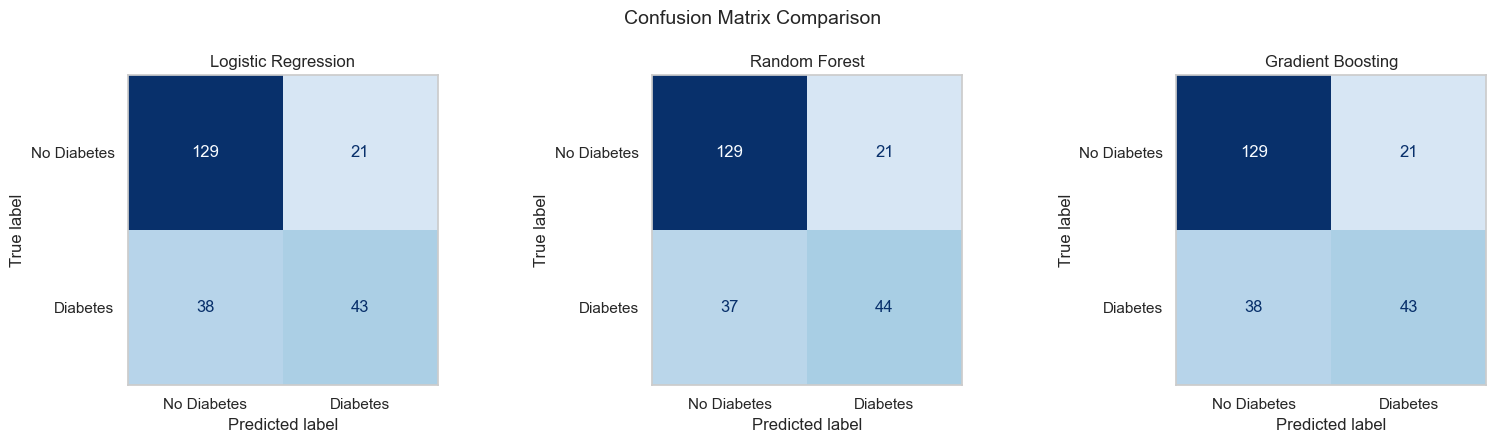

In [64]:
# Predictions from the three trained models
model_predictions = {
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gb_pred
}

# Use the same color scale for all three matrices
max_count = max(
    confusion_matrix(y_test, pred, labels=[0, 1]).max()
    for pred in model_predictions.values()
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, predictions) in zip(
    axes, model_predictions.items()
):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Diabetes", "Diabetes"]
    )

    display_cm.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d",
        im_kw={"vmin": 0, "vmax": max_count}
    )

# Remove grid lines from the confusion matrix
    ax.grid(False)
    
    ax.set_title(name)

plt.suptitle("Confusion Matrix Comparison", fontsize=14)
plt.tight_layout()
plt.show()


In [65]:
# Summarize correct and incorrect predictions
cm_results = []

for name, predictions in model_predictions.items():
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    cm_results.append({
        "Model": name,
        "True Positives": tp,
        "False Negatives": fn,
        "False Positives": fp,
        "True Negatives": tn
    })

cm_summary = pd.DataFrame(cm_results)

display(cm_summary)


,Model,True Positives,False Negatives,False Positives,True Negatives
0,Logistic Regression,43,38,21,129
1,Random Forest,44,37,21,129
2,Gradient Boosting,43,38,21,129


### Confusion Matrix Results

- Random Forest correctly identified 44 of the 81 positive cases, compared with 43 for Logistic Regression and Gradient Boosting.
- All three models produced 21 false positives, but missed 37–38 positive cases. This is a significant limitation if the goal is to identify people who may need further assessment.
- Logistic Regression and Gradient Boosting have identical confusion matrix totals, although their predictions differ on 20 individual test samples. This shows why looking only at overall scores does not tell the whole story.

---

### 8.6 ROC Curve & AUC Comparison

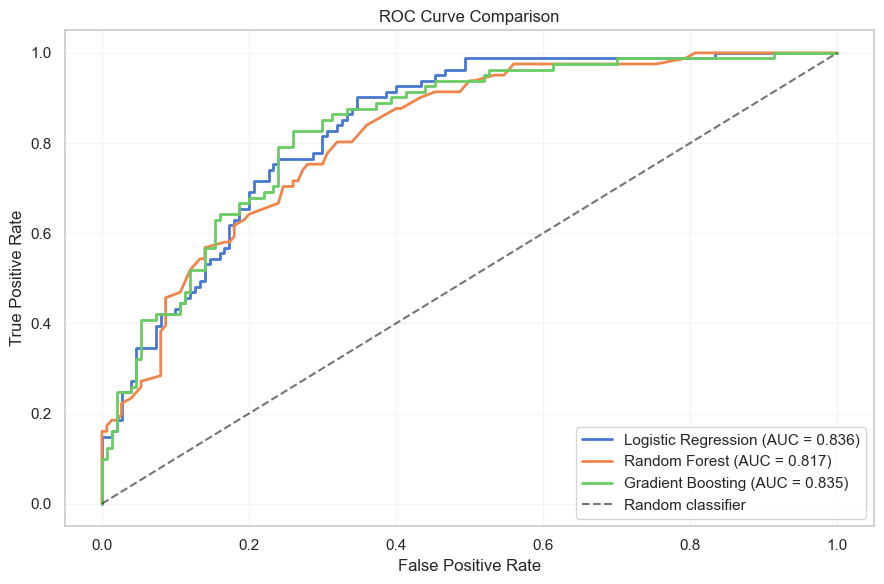

,Model,ROC-AUC
0,Logistic Regression,0.836
1,Random Forest,0.817
2,Gradient Boosting,0.835


In [66]:
# Compare ROC curves for the three trained models
models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_pipeline,
    "Gradient Boosting": gb_pipeline
}

roc_results = []

plt.figure(figsize=(9, 6))

for name, model in models.items():
    # Predicted probabilities for the positive class
    probabilities = model.predict_proba(X_test)[:, 1]

    # ROC curve and AUC
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc_score = roc_auc_score(y_test, probabilities)

    roc_results.append({
        "Model": name,
        "ROC-AUC": auc_score
    })

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    alpha=0.6,
    label="Random classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Display AUC scores
auc_comparison = pd.DataFrame(roc_results)
display(auc_comparison.round(3))



### ROC-AUC Results

- Logistic Regression achieved the highest ROC-AUC (0.836), followed closely by Gradient Boosting (0.835). Random Forest had a slightly lower score (0.817).
- All three models performed better than random classification in terms of ROC-AUC. The difference between Logistic Regression and Gradient Boosting was very small.
- Although the models showed reasonable discrimination, their recall for positive cases was still relatively low at the default classification threshold.
- I will use cross-validation to compare their performance more reliably.




---

### 8.7 Model Performance Comparison

In [68]:
# Compare the three models using the same test set
model_results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    model_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

comparison = pd.DataFrame(model_results)

# Round values for readability
display(comparison.round(3))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.745,0.672,0.531,0.593,0.836
1,Random Forest,0.749,0.677,0.543,0.603,0.817
2,Gradient Boosting,0.745,0.672,0.531,0.593,0.835


### Model Comparison

- `Random Forest` achieved slightly higher accuracy, precision, recall, and F1-score than the other two models. However, the differences were small.
- `Logistic Regression and Gradient Boosting had nearly identical evaluation scores, despite using different modeling approaches.`
- All three models missed around 46–47% of the positive cases at the default threshold. This is an important limitation, especially if the models were intended to help identify individuals who may need further assessment.
- Based on these results, there is no clear overall winner.
- I will compare the models using cross-validation on the training data before making a final recommendation.


---

## 9. Feature Importance - Random Forest

- I used the Random Forest model to check which features contributed most to its predictions.
- The importance scores are based on how much each feature reduces impurity across the trees.
- These scores help describe how the model works, but they do not show whether a feature causes diabetes.


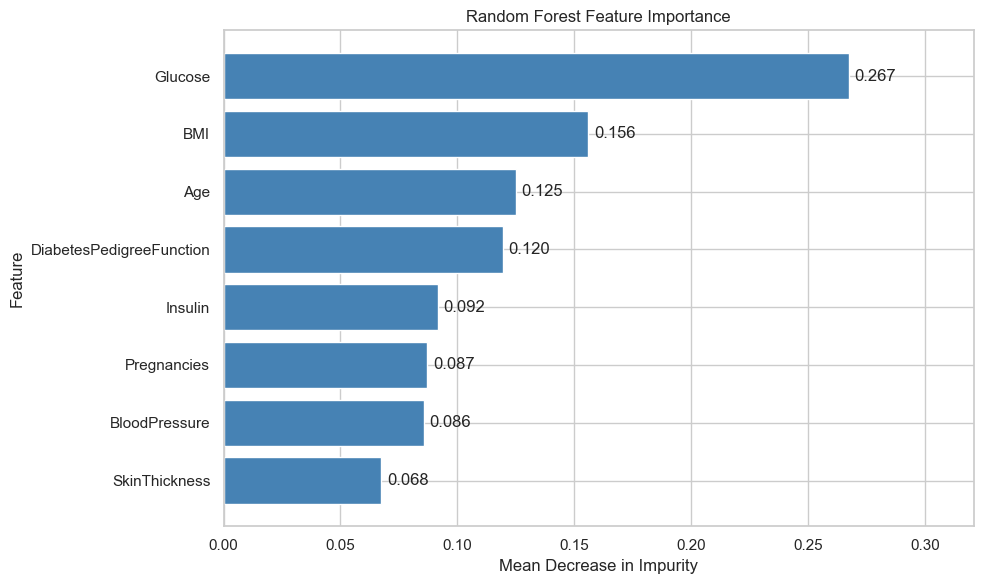

,Importance
Glucose,0.267
BMI,0.156
Age,0.125
DiabetesPedigreeFunction,0.120
Insulin,0.092
Pregnancies,0.087
BloodPressure,0.086
SkinThickness,0.068


In [70]:
# Extract the trained Random Forest from the pipeline
rf_model = rf_pipeline.named_steps["rf"]

# Get feature importance scores
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

# Plot feature importance
plt.figure(figsize=(10, 6))

bars = plt.barh(
    feature_importance.index,
    feature_importance.values,
    color="steelblue"
)

plt.bar_label(
    bars,
    fmt="%.3f",
    padding=4
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Mean Decrease in Impurity")
plt.ylabel("Feature")
plt.xlim(0, feature_importance.max() * 1.2)
plt.tight_layout()
plt.show()

# Display importance scores
display(
    feature_importance
    .sort_values(ascending=False)
    .rename("Importance")
    .to_frame()
    .round(3)
)


### Feature Importance Results

- Glucose had the highest importance score in the Random Forest model (0.267), followed by BMI (0.156) and Age (0.125).

- This suggests that the model relied more heavily on these features when making predictions. However, importance scores do not show the direction of a relationship or establish causation.

- The results should also be interpreted carefully because impurity-based importance can be biased toward certain types of features, and correlated features may share predictive information.

--------------------------

## 10. Cross Validation


- I used 5-fold stratified cross-validation to compare the three models on the training data.
- In each fold, the model is trained on four parts of the data and evaluated on the remaining part. This helps check how consistent the results are across different subsets.
- I included accuracy, precision, recall, F1-score, and ROC-AUC because accuracy alone does not fully describe performance on the positive class.
- The preprocessing steps are included within each pipeline, so the imputer and scaler are fitted separately in each training fold.

### 10.1 Cross-Validation Across Three Models

In [77]:
# Set up stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Metrics used for model comparison
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

# Compare the three pipelines
cv_models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_pipeline,
    "Gradient Boosting": gb_pipeline
}

cv_results = []

for name, pipeline in cv_models.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    result = {"Model": name}

    for metric in scoring:
        values = scores[f"test_{metric}"]

        result[f"{metric}_Mean"] = values.mean()
        result[f"{metric}_Std"] = values.std()

    cv_results.append(result)

# Create a summary table
cv_summary = pd.DataFrame(cv_results)

display(cv_summary.round(3))

,Model,Accuracy_Mean,Accuracy_Std,Precision_Mean,Precision_Std,Recall_Mean,Recall_Std,F1_Mean,F1_Std,ROC_AUC_Mean,ROC_AUC_Std
0,Logistic Regression,0.780,0.034,0.757,0.108,0.573,0.102,0.641,0.065,0.836,0.032
1,Random Forest,0.769,0.025,0.711,0.060,0.583,0.091,0.634,0.055,0.821,0.042
2,Gradient Boosting,0.756,0.042,0.686,0.084,0.578,0.097,0.620,0.069,0.807,0.044


### 10.2 Model Comparison

In [73]:
# Create a compact comparison of mean CV scores
mean_columns = [
    "Accuracy_Mean",
    "Precision_Mean",
    "Recall_Mean",
    "F1_Mean",
    "ROC_AUC_Mean"
]

cv_comparison = cv_summary[
    ["Model"] + mean_columns
].copy()

cv_comparison.columns = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

display(cv_comparison.round(3))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.780,0.757,0.573,0.641,0.836
1,Random Forest,0.769,0.711,0.583,0.634,0.821
2,Gradient Boosting,0.756,0.686,0.578,0.620,0.807


### Cross-Validation Results

- `Logistic Regression` achieved the highest mean accuracy (0.780), precision (0.757), F1-score (0.641), and ROC-AUC (0.836) across the five folds.
- Random Forest had the highest mean recall (0.583), but the difference from Logistic Regression (0.573) was small. Gradient Boosting did not improve the overall results.
- Recall also varied between folds, suggesting that the models' ability to identify positive cases is not entirely consistent across different subsets of the training data.
- Based on these results, `Logistic Regression is a reasonable baseline for further analysis`. However, `recall remains a limitation for all three models.`

---

## 11. Classification Threshold Analysis

- The models missed a considerable number of positive cases at the default threshold of 0.5.
- I wanted to see whether changing the threshold could improve recall and how this would affect precision.
- For this analysis, I used Logistic Regression and out-of-fold predictions from the training data. The test set is not used to select a threshold.

### 11.1 Generate Out-of-Fold Predictions

In [78]:
# Out-of-fold probabilities using training data only
lr_oof_probs = cross_val_predict(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Number of predictions:", len(lr_oof_probs))
print("Training samples:", len(y_train))


Number of predictions: 537
Training samples: 537


### 11.2 Compare Different Thresholds

In [79]:
# Compare classification metrics at different thresholds
thresholds = np.arange(0.20, 0.81, 0.05)

threshold_results = []

for threshold in thresholds:
    predictions = (lr_oof_probs >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        ),
        "Predicted Positives": predictions.sum()
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))


,Threshold,Precision,Recall,F1,Predicted Positives
0,0.20,0.503,0.877,0.639,326
1,0.25,0.544,0.818,0.654,281
2,0.30,0.586,0.765,0.664,244
3,0.35,0.630,0.711,0.668,211
4,0.40,0.665,0.668,0.667,188
5,0.45,0.714,0.615,0.661,161
6,0.50,0.738,0.572,0.645,145
7,0.55,0.769,0.551,0.642,134
8,0.60,0.793,0.513,0.623,121
9,0.65,0.806,0.465,0.590,108


### 11.3 Visualize the Trade-off

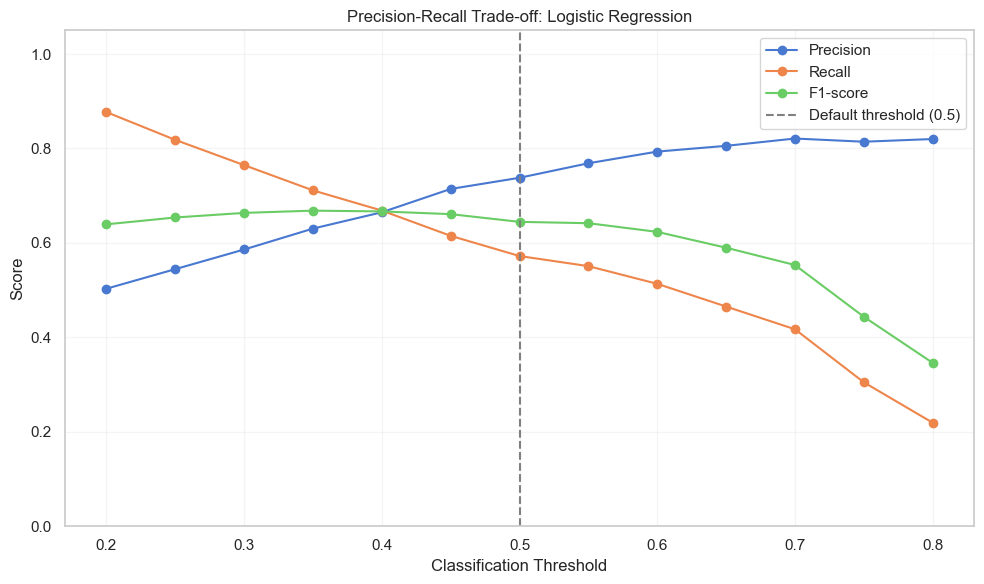

In [80]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1-score"
)

plt.axvline(
    0.5,
    color="gray",
    linestyle="--",
    label="Default threshold (0.5)"
)

plt.title("Precision-Recall Trade-off: Logistic Regression")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 11.4 Explore a Recall Target

In [81]:
# Illustrative target: at least 75% recall
target_recall = 0.75

eligible = threshold_df[
    threshold_df["Recall"] >= target_recall
].copy()

if not eligible.empty:
    candidate = eligible.sort_values(
        ["Precision", "Threshold"],
        ascending=[False, False]
    ).iloc[0]

    print("Candidate threshold:", round(candidate["Threshold"], 2))
    print("Estimated precision:", round(candidate["Precision"], 3))
    print("Estimated recall:", round(candidate["Recall"], 3))
    print("Estimated F1:", round(candidate["F1"], 3))
else:
    print("No tested threshold met the recall target.")


Candidate threshold: 0.3
Estimated precision: 0.586
Estimated recall: 0.765
Estimated F1: 0.664


### Threshold Analysis Results

- `Lowering the classification threshold from 0.50 to 0.30 increased recall from 0.572 to 0.765, while precision decreased from 0.738 to 0.586.`
- The threshold of 0.30 met the illustrative target of at least 75% recall. However, `this improvement came with more false positive predictions.`
- The highest F1-score among the tested thresholds was achieved at 0.35, showing that the preferred threshold depends on the evaluation objective.
- I used out-of-fold predictions from the training data for this analysis. Since the candidate threshold was selected using these results, its reported performance is exploratory rather than an independent final evaluation.
- `The 75% recall target was chosen for demonstration and does not represent a validated clinical requirement.`